# 01 - Data sanity check
Goal: look at the processed data with your own eyes before building anything on it.
**Garbage in, garbage out** applies doubly in finance: a single bad price can create a fake "signal" that a model happily learns.

Run `python -m src.data` from the project root first to create the files.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

PROC = Path("..") / "data" / "processed"
prices = pd.read_parquet(PROC / "adj_close.parquet")   # dates x tickers, adjusted close
volume = pd.read_parquet(PROC / "volume.parquet")      # dates x tickers, shares traded

# Chart styling: thin lines, recessive grid, fixed categorical colour order (validated palette)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "lines.linewidth": 1.4, "axes.edgecolor": "#52514e"})
print("prices:", prices.shape, "| volume:", volume.shape)
print("range :", prices.index.min().date(), "->", prices.index.max().date())

Matplotlib is building the font cache; this may take a moment.


prices: (4238, 500) | volume: (4238, 500)
range : 2010-01-04 -> 2026-11-06


## 1. Well-known stocks, indexed to 100
Raw prices (AAPL ~$200 vs NVDA ~$100...) can't share an axis fairly, and a dual-axis chart misleads. Instead we **index every series to 100 at the start**, so the lines show relative growth. Log scale makes equal *percentage* moves look equal (a move 100->200 looks the same as 200->400).

Things to check: no vertical cliffs (un-adjusted splits would show as sudden 50-90% drops), and the 2020 COVID crash and 2022 bear market should be visible.

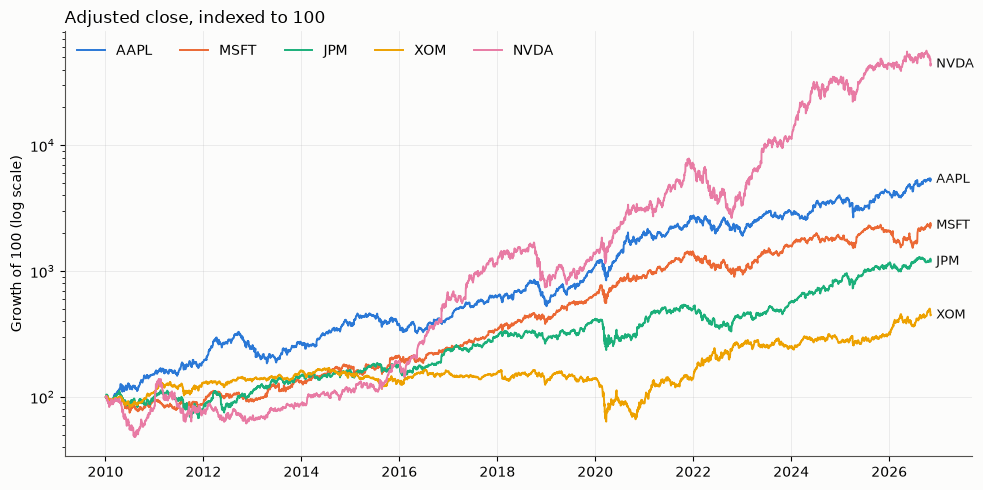

In [2]:
picks = [t for t in ["AAPL", "MSFT", "JPM", "XOM", "NVDA"] if t in prices.columns]
fig, ax = plt.subplots(figsize=(10, 5))
for color, t in zip(COLORS, picks):
    s = prices[t].dropna()
    idx = 100 * s / s.iloc[0]
    ax.plot(idx.index, idx, color=color, label=t)
    ax.annotate(t, (idx.index[-1], idx.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color="#0b0b0b", fontsize=9, va="center")
ax.set_yscale("log"); ax.set_ylabel("Growth of 100 (log scale)")
ax.set_title("Adjusted close, indexed to 100", loc="left")
ax.legend(frameon=False, ncol=len(picks), loc="upper left")
plt.tight_layout(); plt.show()

## 2. Adjusted vs raw: why it matters
Compare AAPL's cumulative return using adjusted close against the raw (split-adjusted-only) `Close` in the raw file. The gap is dividends reinvested.

In [3]:
raw = pd.read_parquet(Path("..") / "data" / "raw" / "prices_raw.parquet")
a = raw[raw.Ticker == "AAPL"]
print("AAPL total growth, Close     :", round(a["Close"].iloc[-1] / a["Close"].iloc[0], 1), "x")
print("AAPL total growth, Adj Close :", round(a["Adj Close"].iloc[-1] / a["Adj Close"].iloc[0], 1), "x  (includes dividends)")

AAPL total growth, Close     : 44.8 x
AAPL total growth, Adj Close : 53.5 x  (includes dividends)


## 3. Missing data
After cleaning, remaining NaNs should be mostly *leading* (stock hadn't IPO'd yet), not holes in the middle.

tickers with ANY missing: 83 of 500

Top 15 by missing days:
Ticker
Q       3978
SNDK    3802
GEV     3581
SOLV    3580
RDDT    3577
VLTO    3461
GEHC    3261
CEG     3032
HOOD    2912
APP     2839
COIN    2838
EXE     2795
ABNB    2754
DASH    2753
PLTR    2704


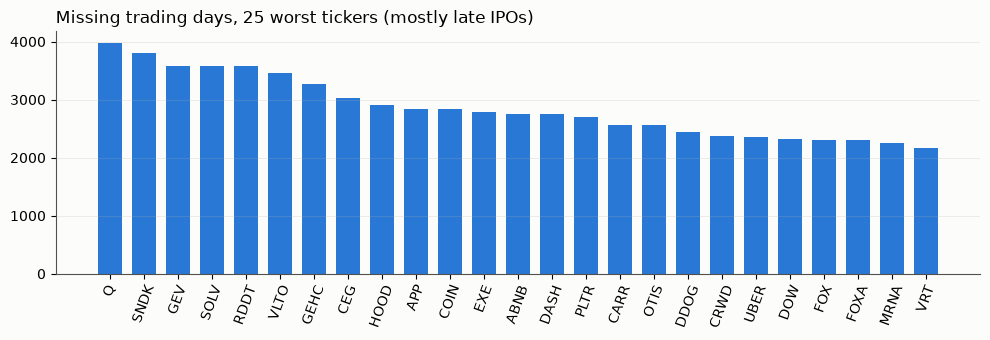

In [4]:
missing = prices.isna().sum().sort_values(ascending=False)
print("tickers with ANY missing:", (missing > 0).sum(), "of", len(missing))
print("\nTop 15 by missing days:"); print(missing.head(15).to_string())

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(missing.head(25).index, missing.head(25).values, color=COLORS[0], width=0.7)
ax.set_title("Missing trading days, 25 worst tickers (mostly late IPOs)", loc="left")
ax.tick_params(axis="x", rotation=70); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

In [5]:
# Interior holes (NaN AFTER a stock's first valid date) are the real red flag
def interior_nans(s):
    first = s.first_valid_index()
    return 0 if first is None else int(s.loc[first:].isna().sum())
holes = prices.apply(interior_nans)
print("Tickers with interior/trailing holes:", int((holes > 0).sum()))
print(holes[holes > 0].sort_values(ascending=False).head(10).to_string())

Tickers with interior/trailing holes: 0
Series([], )


## 4. Summary statistics
Daily returns = percent change of *adjusted* close. Sanity expectations: typical annualized volatility of single stocks is ~20-60%; daily mean ~0.04%; a handful of extreme days is normal (fat tails).

In [6]:
rets = prices.pct_change(fill_method=None)
ann_vol = rets.std() * np.sqrt(252)
print("Daily return, pooled across all stocks:")
print(rets.stack().describe(percentiles=[.001, .01, .5, .99, .999]).round(4).to_string())
print("\nAnnualized volatility across stocks:")
print(ann_vol.describe().round(3).to_string())
print("\nMost volatile:"); print(ann_vol.nlargest(5).round(2).to_string())
print("\nAverage daily dollar volume is the liquidity proxy we will use later")
print("Median shares/day, 5 smallest:"); print(volume.median().nsmallest(5).round(0).to_string())

Daily return, pooled across all stocks:
count    1.994605e+06
mean     7.000000e-04
std      2.060000e-02
min     -5.386000e-01
0.1%    -1.210000e-01
1%      -5.550000e-02
50%      7.000000e-04
99%      5.750000e-02
99.9%    1.298000e-01
max      1.769700e+00

Annualized volatility across stocks:
count    500.000
mean       0.324
std        0.115
min        0.172
25%        0.253
50%        0.296
75%        0.366
max        1.058

Most volatile:
Ticker
SNDK    1.06
CVNA    0.98
MRNA    0.97
BE      0.96
COIN    0.84

Average daily dollar volume is the liquidity proxy we will use later
Median shares/day, 5 smallest:


Ticker
SW           0.0
FERG        95.0
NVR      25000.0
ERIE     55000.0
MTD     144100.0


## 5. Extreme moves - eyeball them
Moves over 50% in a day were flagged by the cleaner (not removed). Real events (earnings shocks, bankruptcies, COVID oil crash) are fine; **spin-offs and bad splits** are data artifacts. Decide for each one.

In [7]:
jumps = pd.read_csv(PROC / "flagged_jumps.csv", parse_dates=["date"])
print(jumps.sort_values("date").to_string(index=False))
print("\nDropped tickers:"); print(pd.read_csv(PROC / "dropped_tickers.csv").to_string(index=False))

      date ticker    return
2012-05-07   VRTX  0.553595
2013-04-19   VRTX  0.619066
2016-04-22    AMD  0.522901
2016-07-05    DHR  0.612184
2019-01-14    PCG -0.523593
2019-01-24    PCG  0.745932
2020-03-09    APA -0.538647
2020-03-09    OXY -0.520138
2020-03-09   TRGP -0.529074
2021-08-04   HOOD  0.504060
2023-06-08   CVNA  0.560206
2024-04-11     GL -0.531402
2024-11-15     BE  0.591867
2025-08-26   ECHO  0.702477
2026-08-19   MRNA  1.769695

Dropped tickers:
ticker                   reason
  FDXF short history (115 days)
  HONA short history (102 days)
  VYLR  short history (27 days)


In [8]:
# Zoom into one flagged event: price window around it
t, d = "DHR", pd.Timestamp("2016-07-05")
print(prices[t].loc[d - pd.Timedelta(days=7): d + pd.Timedelta(days=7)].round(2).to_string())

Date
2016-06-28    40.21
2016-06-29    41.03
2016-06-30    41.39
2016-07-01    41.94
2016-07-05    67.61
2016-07-06    67.79
2016-07-07    67.86
2016-07-08    67.99
2016-07-11    67.34
2016-07-12    67.56
